# Módulo 3 - Punto 3.1: Analisis de texturas

Toda la lógica del cálculo está en `src/modulo3/textura.py`; este notebook se encarga de llamar a los módulos y visualizar los resultados.

In [1]:
# --- Imports de la librería estándar ---
import sys                 
from pathlib import Path   

# --- Configurar la raíz del repositorio ---
# Path.cwd() = carpeta desde donde corre el notebook (normalmente notebooks/).
# Subimos carpetas hasta encontrar config.yaml: esa es la raíz.
# Así funciona tanto si VS Code abre el notebook desde notebooks/ como desde la raíz.
raiz = Path.cwd()
while not (raiz / "config.yaml").exists():
    if raiz.parent == raiz:          # llegamos a "/" sin encontrarlo
        raise FileNotFoundError("No encontré config.yaml en ninguna carpeta superior.")
    raiz = raiz.parent

# Insertamos la raíz al principio de sys.path (posición 0 = máxima prioridad).
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# --- Imports de terceros y propios
import numpy as np  
import pandas as pd # Agregar a requirements
import itertools
import matplotlib.pyplot as plt    
import matplotlib.patches as patches  
import skimage as ski
import cv2



from src.config import cargar_config
from src.modulo1 import carga_muestreo as cm   
from src.modulo1 import calidad_filtrado as cf
from src.modulo2 import segmentacion as seg
from src.modulo2 import morfologia as morf
from src.modulo3 import morfometria as mor
from src.modulo3 import textura as tex



## 1. Carga de Datos y Configuración Global
Se leen los parámetros desde `config.yaml`, se definen las rutas de salida e inicializan las imágenes de trabajo.

In [2]:
# Cargar configuración global
cfg = cargar_config(raiz / "config.yaml")

# Directorio de salida de resultados
carpeta_res = raiz / "results" / "modulo3"
carpeta_res.mkdir(parents=True, exist_ok=True)

# Carga de imagen y extracción de la ROI
img = cm.obtener_frame(cfg, raiz)
roi = cm.recortar_roi(img, cfg["roi"]) 
roi_grises = cf.conv_grises(roi) 

# Parámetros del módulo 1.2
p = cfg["modulo1_2"]
k = p["kernel"] #--> tamaño del kernel para filtrado
clahe_clip = p["clahe_clip"] #--> clip para CLAHE
clahe_grilla = p["clahe_grilla"] #--> tamaño de la grilla para CLAHE
sigma=p["gauss_sigma"]


# Parámetros del módulo 2
n = cfg["modulo2"]["snake"]
factor_radio_inicial = n["factor_radio_inicial"]
k=n["suavizado_k"]
sigma=n["suavizado_sigma"]
alpha=n["alpha"]
beta=n["beta"]
gamma=n["gamma"]

w = cfg["modulo2"]["watershed"]
factor_interior= w["factor_interior"]
factor_anillo_interior= w["factor_anillo_interior"]
factor_anillo_exterior= w["factor_anillo_exterior"]

km = cfg["modulo2"]["kmeans"]
factor_ventana=km["factor_ventana"]


print(f"Resultados en: {carpeta_res}")

Resultados en: c:\Users\delca\Downloads\Guia-de-imagenes-biomedicas-G9-PSIB-main\results\modulo3


## 2. Pre segmentado

Para aplicar **Otsu**, **Snake** y **Watershed**, se requiere trabajar sobre la imagen en escala de grises. 
Para aplicar **K-means**, se utiliza la imagen a color.

Dado el bajo contraste inicial observado en el módulo 1, aplicamos ecualización **CLAHE** (por bloques) para resaltar la pupila respecto al iris y la esclerótica.

> **Nota sobre filtrado:** Tras realizar pruebas con distintos filtros, se decidió no aplicar ningún filtrado adicional debido a que degradaban significativamente la nitidez de la imagen.

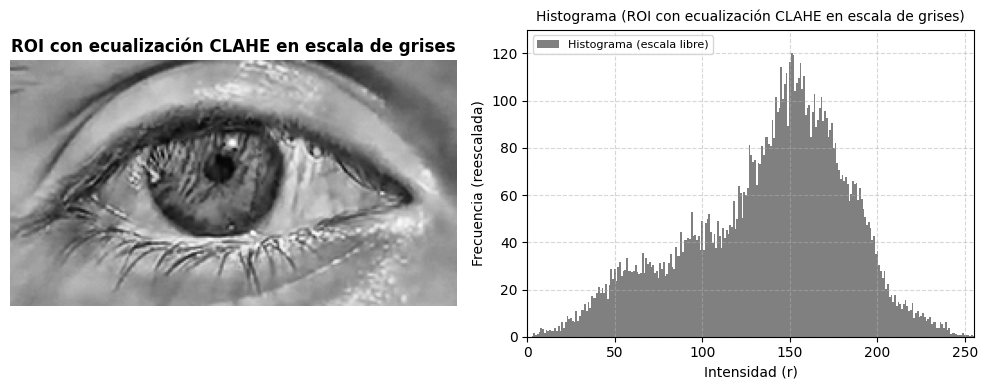

In [3]:
# Aplicar ecualización CLAHE
img_grises_clahe = cf.aplicar_clahe(roi_grises, clahe_clip, clahe_grilla)

# Visualización ROI + HISTOGRAMA
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
img = img_grises_clahe
titulo = "ROI con ecualización CLAHE en escala de grises"

# Imagen ecualizada
axes[0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(titulo, fontsize=12, fontweight="bold")
axes[0].axis("off")  

# Histograma 
hist_og = cf.histograma(img) if hasattr(cf, 'histograma') else np.bincount(img.ravel(), minlength=256)
hist_og = np.asarray(hist_og, dtype=float)

axes[1].bar(range(256), hist_og / hist_og.max() * 120, width=1, color="gray", edgecolor="none", label="Histograma (escala libre)")
axes[1].set_xlim(0, 255)
axes[1].set_ylim(0, 130)  
axes[1].set_xlabel("Intensidad (r)")
axes[1].set_ylabel("Frecuencia (reescalada)")
axes[1].set_title(f"Histograma ({titulo})", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 3.1 Análisis de texturas 
Primero utilizando la logica de `src/modulo3/textura.py` y con la segmentación realizada en el módulo 2 encontramos el area, el perimetro y el centroide de la pupila. 
Luego  analizamos la textura de la pupila y del iris (estroma) en cada canal de color R, G y B por separado. Toda la lógica está en `src/modulo3/textura.py`.

- Regiones: la pupila sale de la máscara de Watershed (Módulo 2). El iris es el círculo del iris estimado por `estimar_pupila(..., devolver_iris=True)` menos la pupila. Solo cuentan los píxeles dentro de cada máscara.
- Primer orden (histograma): media, desvío estándar, entropía de Shannon (bits, sobre el histograma cuantizado) y asimetría (tercer momento estandarizado).
- Segundo orden (GLCM): distancia 1, 4 ángulos (0°, 45°, 90°, 135°) promediados, matriz simétrica y normalizada, calculada solo con pares de píxeles dentro de la máscara. Atributos: contraste, homogeneidad, energía y correlación.
- Cuantización: 32 niveles de gris por canal (más abajo se prueba con 16 y 64 para ver si las conclusiones dependen de esa elección).

### 3.1.1 Calculo de parametros de la pupila

Utilizando la lógica de `src/modulo3/textura.py` y la segmentación realizada en el módulo 2, encontramos el centro de la pupila , el area y el perimetro de la misma.

In [4]:
res = mor.segmentar_pupila_erosionada(roi, cfg)     # Watershed
m = res["mascara"]
d = mor.descriptores_forma(m)
if d is None:
    print("No se detectó pupila en este frame.")
else:
    for k, v in d.items():
        print(f"{k}: {v:.3f}")

area_px: 270.000
perimetro_px: 67.355
circularidad: 0.666
excentricidad: 0.610
xc: 115.867
yc: 58.896


#### 3.1.2 Primer orden: media, desvío, entropía y asimetría por canal

Píxeles de pupila: 270  |  píxeles de iris (sin pupila): 3783


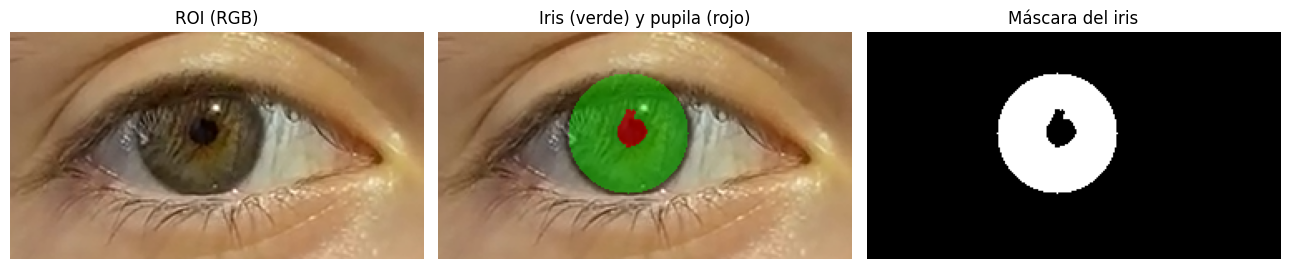

In [5]:
from src.modulo3 import textura as tex

niveles = 32
reg = tex.segmentar_regiones(roi, cfg)
m_pupila, m_iris = reg["mascara_pupila"], reg["mascara_iris"]
hay_iris = m_iris is not None

if not hay_iris:
    print("No se detectó iris/pupila en este frame (¿parpadeo?). Se omite el análisis de textura.")
else:
    print(f"Píxeles de pupila: {(m_pupila > 0).sum()}  |  píxeles de iris (sin pupila): {(m_iris > 0).sum()}")

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    axes[0].imshow(roi); axes[0].set_title("ROI (RGB)")
    sup = roi.copy()
    sup[m_iris > 0] = (0.6 * sup[m_iris > 0] + 0.4 * np.array([0, 255, 0])).astype(np.uint8)
    sup[m_pupila > 0] = (0.5 * sup[m_pupila > 0] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    axes[1].imshow(sup); axes[1].set_title("Iris (verde) y pupila (rojo)")
    axes[2].imshow(m_iris, cmap="gray"); axes[2].set_title("Máscara del iris")
    for a in axes: a.axis("off")
    plt.tight_layout()
    plt.savefig(carpeta_res / "3_1_regiones.png", dpi=150, bbox_inches="tight")
    plt.show()

PRIMER ORDEN (valores originales 0-255; entropía en bits sobre 32 niveles, máx = 5.00)


media  desvio  entropia  asimetria
region canal                                     
iris   R      77.461  19.249     3.160      1.927
       G      61.636  19.825     3.192      1.904
       B      37.748  19.377     3.090      2.375
pupila R      32.559  14.050     2.675      0.742
       G      18.781  12.615     2.524      0.647
       B      11.074  10.854     2.027      0.699

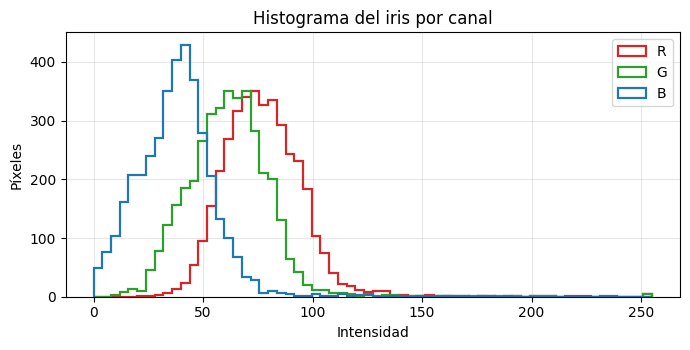

In [6]:
if hay_iris:
    t_iris = tex.tabla_textura(roi, m_iris, niveles=niveles, region="iris")
    t_pupila = tex.tabla_textura(roi, m_pupila, niveles=niveles, region="pupila")
    t_todo = pd.concat([t_iris, t_pupila])

    print("PRIMER ORDEN (valores originales 0-255; entropía en bits sobre %d niveles, máx = %.2f)" % (niveles, np.log2(niveles)))
    display(t_todo[list(tex.ATRIBUTOS_1)].round(3))

    # Histogramas por canal dentro del iris
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for i, (nombre, col) in enumerate(zip(tex.CANALES, ["tab:red", "tab:green", "tab:blue"])):
        ax.hist(roi[..., i][m_iris > 0], bins=64, range=(0, 255), histtype="step", color=col, label=nombre, lw=1.6)
    ax.set_xlabel("Intensidad"); ax.set_ylabel("Píxeles")
    ax.set_title("Histograma del iris por canal"); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(carpeta_res / "3_1_histogramas_iris.png", dpi=150, bbox_inches="tight")
    plt.show()

#### 3.1.3 Segundo orden: GLCM (contraste, homogeneidad, energía y correlación)

SEGUNDO ORDEN - GLCM (distancia 1, promedio de 4 ángulos)


contraste  homogeneidad  energia  correlacion
region canal                                               
iris   R          2.621         0.630    0.192        0.774
       G          2.641         0.630    0.189        0.786
       B          2.594         0.642    0.204        0.781
pupila R          1.302         0.690    0.283        0.778
       G          1.065         0.723    0.292        0.776
       B          0.638         0.791    0.424        0.788

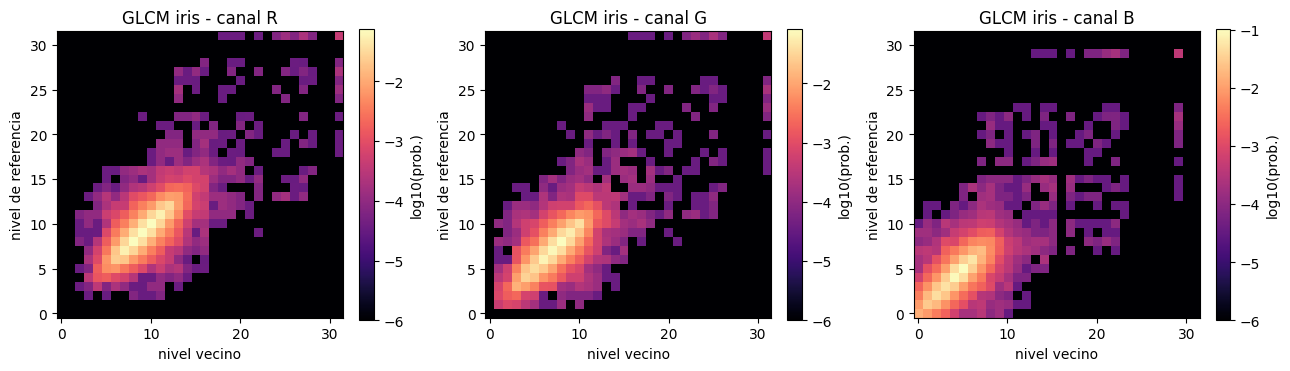

In [7]:
if hay_iris:
    print("SEGUNDO ORDEN - GLCM (distancia 1, promedio de 4 ángulos)")
    display(t_todo[list(tex.ATRIBUTOS_2)].round(3))

    # GLCM del iris (promedio de los 4 ángulos), una por canal
    G = tex.glcm(roi, m_iris, niveles=niveles)
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    for ax, nombre in zip(axes, tex.CANALES):
        mat = G[nombre][:, :, 0, :].mean(axis=-1)
        im = ax.imshow(np.log10(mat + 1e-6), cmap="magma", origin="lower")
        ax.set_title(f"GLCM iris - canal {nombre}")
        ax.set_xlabel("nivel vecino"); ax.set_ylabel("nivel de referencia")
        plt.colorbar(im, ax=ax, fraction=0.046, label="log10(prob.)")
    plt.tight_layout()
    plt.savefig(carpeta_res / "3_1_glcm_iris.png", dpi=150, bbox_inches="tight")
    plt.show()

    t_todo.round(4).to_csv(carpeta_res / "3_1_tabla_textura.csv")

#### 3.1.3 Discusión: ¿qué canal aporta mayor riqueza textural del estroma iridiano?

Criterio: se considera más rico el canal con mayor desvío, mayor entropía y mayor contraste y con menor homogeneidad y menor energía (una GLCM concentrada en la diagonal y con energía alta describe una zona lisa). Cada canal recibe un puesto (1 = más textura) por criterio y se promedian; menor puntaje = canal más rico. Media, asimetría y correlación no entran: describen brillo, forma del histograma y linealidad, no cuánta textura hay.

Como control se repite con 16 y 64 niveles de cuantización y se calcula el coeficiente de variación (desvío / media).

RANKING DEL IRIS (32 niveles) - puestos por criterio (1 = más textura) y puntaje (menor = mejor)


,desvio,entropia,contraste,homogeneidad,energia,puntaje
canal,,,,,,
G,1.0,1.0,1.0,2.0,1.0,1.2
R,3.0,2.0,2.0,1.0,2.0,2.0
B,2.0,3.0,3.0,3.0,3.0,2.8


Canal más rico: G

ROBUSTEZ: puntaje y puesto final según la cuantización


puntaje           puesto_final          
niveles      16   32   64           16   32   64
canal                                           
B           2.8  2.8  2.6          3.0  3.0  3.0
G           1.4  1.2  1.2          1.0  1.0  1.0
R           1.8  2.0  2.2          2.0  2.0  2.0


COEFICIENTE DE VARIACIÓN (desvío / media) en el iris


,coef_variacion
canal,
R,0.248
G,0.322
B,0.513


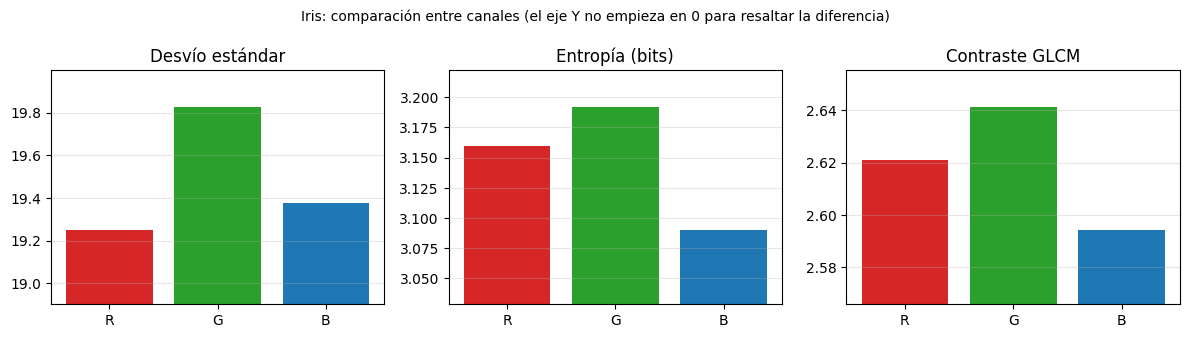

In [8]:
if hay_iris:
    rank = tex.ranking_canales(t_iris)
    print(f"RANKING DEL IRIS ({niveles} niveles) - puestos por criterio (1 = más textura) y puntaje (menor = mejor)")
    display(rank.round(2))
    print("Canal más rico:", tex.ganador(t_iris))

    # Robustez frente a la cuantización
    filas = []
    for nv in (16, 32, 64):
        t = tex.tabla_textura(roi, m_iris, niveles=nv, region="iris")
        r = tex.ranking_canales(t)
        for c in tex.CANALES:
            filas.append({"niveles": nv, "canal": c, "puntaje": r.loc[c, "puntaje"],
                          "puesto_final": int(r["puntaje"].rank(method="min")[c]),
                          "entropia": t.loc[("iris", c), "entropia"],
                          "contraste": t.loc[("iris", c), "contraste"]})
    robustez = pd.DataFrame(filas).pivot(index="canal", columns="niveles", values=["puntaje", "puesto_final"])
    print("\nROBUSTEZ: puntaje y puesto final según la cuantización")
    display(robustez.round(2))

    # Control: variabilidad relativa al brillo del canal
    print("\nCOEFICIENTE DE VARIACIÓN (desvío / media) en el iris")
    display(tex.coef_variacion(t_iris).round(3).to_frame())

    # Figura resumen
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
    cols = ["tab:red", "tab:green", "tab:blue"]
    for ax, (atrib, tit) in zip(axes, [("desvio", "Desvío estándar"), ("entropia", "Entropía (bits)"), ("contraste", "Contraste GLCM")]):
        vals = [t_iris.loc[("iris", c), atrib] for c in tex.CANALES]
        ax.bar(tex.CANALES, vals, color=cols)
        ax.set_title(tit); ax.grid(axis="y", alpha=0.3)
        lo, hi = min(vals), max(vals)
        ax.set_ylim(lo - 0.6 * (hi - lo + 1e-9) - 1e-9 if hi > lo else 0, hi + 0.3 * (hi - lo + 1e-9))
    plt.suptitle("Iris: comparación entre canales (el eje Y no empieza en 0 para resaltar la diferencia)", fontsize=10)
    plt.tight_layout()
    plt.savefig(carpeta_res / "3_1_comparacion_canales.png", dpi=150, bbox_inches="tight")
    plt.show()

**Resultados en el iris** (`frame_1_1.png`, 32 niveles de cuantización):

- Desvío estándar: G 19.8 > B 19.4 > R 19.2.
- Entropía: G 3.19 > R 3.16 > B 3.09 bits (máximo posible 5.00).
- Contraste GLCM: G 2.64 > R 2.62 > B 2.59. Energía: G 0.189 < R 0.192 < B 0.204. Homogeneidad: R y G 0.630, B 0.642.
- Ranking final: G (puntaje 1.2), R (2.0), B (2.8). El orden se mantiene con 16 y 64 niveles.

Lectura. En este frame el canal verde es el que aporta la mayor riqueza textural del estroma, seguido por el rojo; el azul es el que menos. 